# Khám phá dữ liệu giá JPX

Ghép hai tệp giá, kiểm tra khóa và minh họa cách tính nhãn. [Notebook chính](../jpx_overview.ipynb)

Tổng quan dữ liệu gốc mô tả độ phủ của hai nguồn. Các phép phân tích liên quan đến chọn mô hình dùng phần phát triển trước 09/12/2021.

[Quyết định tiền xử lý](../../reports/jpx_release.md#dữ-liệu-và-quyết-định-tiền-xử-lý)

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

relative_path = Path("data/raw/train_files/stock_prices.csv")
cwd = Path.cwd()
project_root = next(
    (folder for folder in (cwd, *cwd.parents) if (folder / relative_path).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(relative_path)

read_options = {"parse_dates": ["Date"], "float_precision": "round_trip"}
train_prices = pd.read_csv(project_root / relative_path, **read_options)
supplemental_prices = pd.read_csv(
    project_root / "data/raw/supplemental_files/stock_prices.csv", **read_options
)

keys = ["Date", "SecuritiesCode"]
if not train_prices.columns.equals(supplemental_prices.columns):
    raise ValueError("Hai tệp có cấu trúc cột khác nhau.")
if not train_prices.dtypes.equals(supplemental_prices.dtypes):
    raise ValueError("Hai tệp có kiểu dữ liệu khác nhau.")

train_end = train_prices["Date"].max()
supplemental_start = supplemental_prices["Date"].min()
if train_end >= supplemental_start:
    raise ValueError("Khoảng ngày của hai nguồn chồng lấn hoặc sai thứ tự.")

prices = pd.concat([train_prices, supplemental_prices], ignore_index=True)
if prices[["RowId", *keys]].isna().any().any():
    raise ValueError("Phát hiện khóa bị thiếu.")
if prices.duplicated(keys).any() or prices["RowId"].duplicated().any():
    raise ValueError("Phát hiện khóa trùng sau khi ghép.")

prices = prices.sort_values(keys, ignore_index=True)
print(f"Số dòng: {len(train_prices):,} + {len(supplemental_prices):,} = {len(prices):,}")
print(f"Số cột: {prices.shape[1]}")
print(f"Khoảng dữ liệu: {prices['Date'].min():%Y-%m-%d} đến {prices['Date'].max():%Y-%m-%d}")
print(f"Ranh giới hai nguồn: {train_end:%Y-%m-%d} → {supplemental_start:%Y-%m-%d}")
del train_prices, supplemental_prices
display(prices.head())

Số dòng: 2,332,531 + 269,881 = 2,602,412
Số cột: 12
Khoảng dữ liệu: 2017-01-04 đến 2022-06-24
Ranh giới hai nguồn: 2021-12-03 → 2021-12-06


,RowId,Date,SecuritiesCode,Open,High,Low,Close,Volume,AdjustmentFactor,ExpectedDividend,SupervisionFlag,Target
0,20170104_1301,2017-01-04,1301,2734.0,2755.0,2730.0,2742.0,31400,1.0,NaN,False,0.000730
1,20170104_1332,2017-01-04,1332,568.0,576.0,563.0,571.0,2798500,1.0,NaN,False,0.012324
2,20170104_1333,2017-01-04,1333,3150.0,3210.0,3140.0,3210.0,270800,1.0,NaN,False,0.006154
3,20170104_1376,2017-01-04,1376,1510.0,1550.0,1510.0,1550.0,11300,1.0,NaN,False,0.011053
4,20170104_1377,2017-01-04,1377,3270.0,3350.0,3270.0,3330.0,150800,1.0,NaN,False,0.003026


Hai nguồn nối tiếp từ 03/12 sang 06/12/2021 và tạo thành 2.602.412 dòng. Cả điều kiện về kiểu dữ liệu và khóa duy nhất đều qua kiểm tra, nên có thể dùng một lịch phiên chung cho các bước sau.

## Kiểu dữ liệu và thống kê mô tả

In [2]:
prices.info(show_counts=True)
numeric_columns = ["Open", "High", "Low", "Close", "Volume", "AdjustmentFactor", "ExpectedDividend", "Target"]
cutoff_eda = pd.Timestamp("2021-12-09")
eda_calendar = pd.DatetimeIndex(prices["Date"].unique()).sort_values()
eda_end = prices["Date"].map(pd.Series(eda_calendar, index=eda_calendar).shift(-2))
development_prices = prices.loc[prices["Date"].lt(cutoff_eda)].copy()
development_prices["Target"] = development_prices["Target"].where(eda_end.lt(cutoff_eda))
display(development_prices[numeric_columns].describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2602412 entries, 0 to 2602411
Data columns (total 12 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   RowId             2602412 non-null  object        
 1   Date              2602412 non-null  datetime64[ns]
 2   SecuritiesCode    2602412 non-null  int64         
 3   Open              2593986 non-null  float64       
 4   High              2593986 non-null  float64       
 5   Low               2593986 non-null  float64       
 6   Close             2593986 non-null  float64       
 7   Volume            2602412 non-null  int64         
 8   AdjustmentFactor  2602412 non-null  float64       
 9   ExpectedDividend  20876 non-null    float64       
 10  SupervisionFlag   2602412 non-null  bool          
 11  Target            2602166 non-null  float64       
dtypes: bool(1), datetime64[ns](1), float64(7), int64(2), object(1)
memory usage: 220.9+ MB


,count,mean,std,min,25%,50%,75%,max
Open,2330905.0,2595.020241,3.579609e+03,14.000000,1022.000000,1812.0,3030.000000,1.099500e+05
High,2330905.0,2627.060310,3.621812e+03,15.000000,1035.000000,1834.0,3070.000000,1.105000e+05
Low,2330905.0,2561.725350,3.535852e+03,13.000000,1009.000000,1790.0,2995.500000,1.072000e+05
Close,2330905.0,2594.549111,3.578987e+03,14.000000,1022.000000,1812.0,3030.000000,1.095500e+05
Volume,2338531.0,691698.029062,3.907689e+06,0.000000,30300.000000,107100.0,402000.000000,6.436540e+08
AdjustmentFactor,2338531.0,1.000506,6.764425e-02,0.100000,1.000000,1.0,1.000000,2.000000e+01
ExpectedDividend,18865.0,22.017730,2.988245e+01,0.000000,5.000000,15.0,30.000000,1.070000e+03
Target,2334293.0,0.000449,2.339567e-02,-0.578541,-0.010494,0.0,0.010535,1.119512e+00


Bảng thống kê mô tả dùng phần phát triển và các nhãn đã hoàn tất trước mốc khóa. Các cực trị ở xa nửa giữa phân bố, nên hồi quy bình phương sai số cần được đối chiếu với mất mát bền vững.

Theo [đặc tả giá JPX](https://www.kaggle.com/competitions/jpx-tokyo-stock-exchange-prediction/data):

- `AdjustmentFactor` — hệ số quy đổi giá và khối lượng khi chia tách hoặc gộp cổ phiếu. Cổ tức nằm ngoài hệ số này.
- `ExpectedDividend` — cổ tức dự kiến cho ngày giao dịch không hưởng quyền, được ghi nhận trước ngày không hưởng cổ tức hai ngày làm việc. Cột gắn với sự kiện, nên cần xét ý nghĩa của ô trống trước khi xử lý.
- `SupervisionFlag` — cờ đánh dấu mã thuộc diện giám sát hoặc chuẩn bị hủy niêm yết.

## Giá trị thiếu và khóa ngày–mã

In [3]:
missing = prices.isnull().sum()
display(pd.DataFrame({
    "Số giá trị thiếu": missing,
    "Tỷ lệ thiếu (%)": (missing / len(prices) * 100).round(4),
}).sort_values("Số giá trị thiếu", ascending=False))

ohlc = ["Open", "High", "Low", "Close"]
missing_ohlc = prices[ohlc].isnull().all(axis=1)
session_count = prices.groupby("Date")["SecuritiesCode"].nunique()

display(pd.Series({
    "Dòng trùng khóa (Date, SecuritiesCode)": prices.duplicated(["Date", "SecuritiesCode"]).sum(),
    "Dòng trùng RowId": prices["RowId"].duplicated().sum(),
    "Dòng thiếu cả bốn giá OHLC": missing_ohlc.sum(),
    "Dòng thiếu cả bốn giá OHLC và Volume = 0": (missing_ohlc & prices["Volume"].eq(0)).sum(),
    "Số phiên quan sát": session_count.size,
    "Số mã khác nhau": prices["SecuritiesCode"].nunique(),
}))
display(session_count.describe()[["min", "50%", "max"]].rename("Số mã mỗi phiên"))

,Số giá trị thiếu,Tỷ lệ thiếu (%)
ExpectedDividend,2581536,99.1978
Open,8426,0.3238
High,8426,0.3238
Close,8426,0.3238
Low,8426,0.3238
Target,246,0.0095
RowId,0,0.0000
Date,0,0.0000
SecuritiesCode,0,0.0000
Volume,0,0.0000


Dòng trùng khóa (Date, SecuritiesCode)         0
Dòng trùng RowId                               0
Dòng thiếu cả bốn giá OHLC                  8426
Dòng thiếu cả bốn giá OHLC và Volume = 0    8426
Số phiên quan sát                           1337
Số mã khác nhau                             2000
dtype: int64

min    1865.0
50%    1949.0
max    2000.0
Name: Số mã mỗi phiên, dtype: float64

Có 8.426 dòng thiếu đồng thời cả bốn giá, tất cả có khối lượng bằng 0. Các phiên vẫn nằm trong lịch, còn cửa sổ đặc trưng giữ dấu thiếu giá ở các điểm này. `ExpectedDividend` có tỷ lệ trống 99,20% vì chỉ xuất hiện quanh sự kiện.

## Target theo từng mã

In [4]:
from decimal import Decimal, ROUND_HALF_UP

sessions = pd.DatetimeIndex(prices["Date"].unique()).sort_values()
label_end_by_date = pd.Series(sessions, index=sessions).shift(-2)
label_end = prices["Date"].map(label_end_by_date)

# Đếm nhãn của nguồn gốc cần giá từ giai đoạn bổ sung để hoàn tất.
cross_boundary = (
    prices["Date"].le(train_end)
    & label_end.ge(supplemental_start)
    & prices["Target"].notna()
)
display(prices.loc[cross_boundary].groupby("Date")["Target"].count().rename(
    "Số nhãn có phiên t+2 ở giai đoạn bổ sung"
))
print("Số nhãn có sẵn nhưng phiên t+2 nằm ngoài tệp ghép:", (
    label_end.isna() & prices["Target"].notna()
).sum())

# Minh họa cho mã 1301. Giữ đủ lịch phiên để shift không nhảy qua phiên thiếu của mã.
symbol = 1301
one_stock = prices.loc[
    prices["SecuritiesCode"].eq(symbol), ["Date", "Close", "AdjustmentFactor", "Target"]
].set_index("Date").reindex(sessions)
one_stock.index.name = "Phiên t"

# Điều chỉnh ngược để đối chiếu nhãn lịch sử.
factor = one_stock["AdjustmentFactor"].iloc[::-1].cumprod().iloc[::-1]
adjusted = (one_stock["Close"] * factor).map(
    lambda value: float(Decimal(str(value)).quantize(Decimal("0.1"), rounding=ROUND_HALF_UP)),
    na_action="ignore",
)
session_dates = pd.Series(sessions, index=sessions)
result = pd.DataFrame({
    "Phiên t+1": session_dates.shift(-1),
    "Phiên t+2": session_dates.shift(-2),
    "Giá điều chỉnh t+1": adjusted.shift(-1),
    "Giá điều chỉnh t+2": adjusted.shift(-2),
    "Target gốc": one_stock["Target"],
})
result["Target tính lại"] = result["Giá điều chỉnh t+2"] / result["Giá điều chỉnh t+1"] - 1
result["Sai số tuyệt đối"] = (result["Target tính lại"] - result["Target gốc"]).abs()
print(f"Mã cổ phiếu: {symbol}")
display(result.loc["2021-12-01":"2021-12-07"].round(8))

Date
2021-12-02    2000
2021-12-03    2000
Name: Số nhãn có phiên t+2 ở giai đoạn bổ sung, dtype: int64

Số nhãn có sẵn nhưng phiên t+2 nằm ngoài tệp ghép: 3992
Mã cổ phiếu: 1301


,Phiên t+1,Phiên t+2,Giá điều chỉnh t+1,Giá điều chỉnh t+2,Target gốc,Target tính lại,Sai số tuyệt đối
Phiên t,,,,,,,
2021-12-01,2021-12-02,2021-12-03,2933.0,2982.0,0.016706,0.016706,0.0
2021-12-02,2021-12-03,2021-12-06,2982.0,2971.0,-0.003689,-0.003689,0.0
2021-12-03,2021-12-06,2021-12-07,2971.0,3065.0,0.031639,0.031639,0.0
2021-12-06,2021-12-07,2021-12-08,3065.0,3055.0,-0.003263,-0.003263,0.0
2021-12-07,2021-12-08,2021-12-09,3055.0,3085.0,0.009820,0.009820,0.0


Ở hai phiên cuối tệp train có 4.000 nhãn mà ngày hoàn tất rơi vào tệp bổ sung. Mã 1301 minh họa cách giá xuyên ranh giới tệp tái tạo đúng nhãn. Đoạn quy đổi ngược đến cuối tệp phục vụ đối chiếu lịch sử. Đặc trưng dự báo chỉ dùng dữ liệu đến phiên tín hiệu.

## Minh họa xếp hạng trong một phiên

In [5]:
# Xếp theo lợi nhuận đã xảy ra để minh họa cách đọc hạng.
day = pd.Timestamp("2021-12-03")
known_returns = prices.loc[prices["Date"].eq(day), ["SecuritiesCode", "Target"]].dropna()
ranked = known_returns.sort_values(["Target", "SecuritiesCode"], ascending=[False, True])
ranked = ranked.reset_index(drop=True)
ranked.index.name = "Hạng trên Target đã biết"
print(f"Phiên {day:%Y-%m-%d} | Số mã có nhãn: {len(ranked):,}")
display(pd.concat([ranked.head(3), ranked.tail(3)]).round(6))

Phiên 2021-12-03 | Số mã có nhãn: 2,000


,SecuritiesCode,Target
Hạng trên Target đã biết,,
0,4699,0.187970
1,1873,0.186782
2,6779,0.159624
1997,2158,-0.091797
1998,6718,-0.092211
1999,9919,-0.224215


Mã 4699 đứng đầu vì lợi nhuận **đã quan sát** khoảng +18,80%, còn mã 9919 đứng cuối với −22,42%. Đây là cách đọc thứ hạng khi biết kết quả, dùng để minh họa hai đầu danh mục.

## Định danh và số giá trị duy nhất

In [6]:
expected_row_id = prices["Date"].dt.strftime("%Y%m%d") + "_" + prices["SecuritiesCode"].astype(str)
print(bool(prices["RowId"].eq(expected_row_id).all()))

True


`True` xác nhận toàn bộ `RowId` khớp quy ước ngày–mã. Có thể dùng khóa `(Date, SecuritiesCode)` để ghép nhãn và dự báo dù thứ tự dòng thay đổi.

In [7]:
display(prices.nunique(dropna=True).rename("Số giá trị duy nhất (bỏ qua ô trống)"))

RowId               2602412
Date                   1337
SecuritiesCode         2000
Open                  23582
High                  24438
Low                   24354
Close                 24523
Volume                93490
AdjustmentFactor         19
ExpectedDividend        489
SupervisionFlag           2
Target               374173
Name: Số giá trị duy nhất (bỏ qua ô trống), dtype: int64

`RowId` có đúng 2.602.412 giá trị duy nhất. Mỗi ngày chỉ có một phần hoặc toàn bộ 2.000 mã, vì vậy số hạng cần tạo được xác định theo từng phiên.

## Open và Close trong cùng phiên

,Open,Close
0.25,1022.0,1022.0
0.50,1812.0,1812.0
0.75,3030.0,3030.0


Tương quan Pearson của mức giá: 0.999731


P1 và P99 của biến động trong phiên: -5.06%, 5.68%


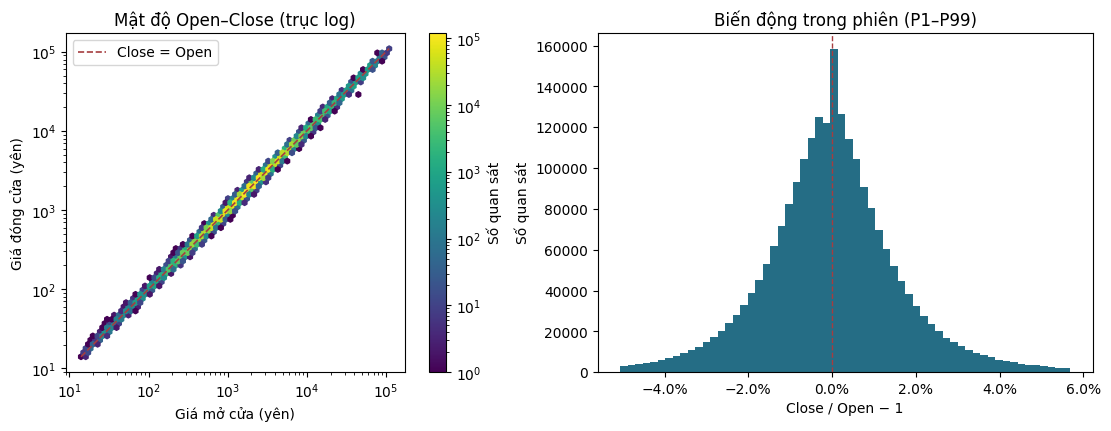

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

paired = development_prices[["Open", "Close"]].dropna()
paired = paired.loc[paired["Open"].gt(0) & paired["Close"].gt(0)]
within_day_return = paired["Close"].div(paired["Open"]).sub(1)
display(paired.quantile([0.25, 0.50, 0.75]))
print(f"Tương quan Pearson của mức giá: {paired['Open'].corr(paired['Close']):.6f}")

fig, (ax_price, ax_return) = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
density = ax_price.hexbin(
    paired["Open"], paired["Close"], xscale="log", yscale="log",
    gridsize=65, bins="log", mincnt=1, cmap="viridis",
)
limits = [paired.min().min(), paired.max().max()]
ax_price.plot(limits, limits, "--", color="#A63D40", lw=1.2, label="Close = Open")
ax_price.set(xlabel="Giá mở cửa (yên)", ylabel="Giá đóng cửa (yên)", title="Mật độ Open–Close (trục log)")
ax_price.set_aspect("equal", adjustable="box")
ax_price.legend(loc="upper left")
fig.colorbar(density, ax=ax_price, label="Số quan sát")

lower, upper = within_day_return.quantile([0.01, 0.99])
central_returns = within_day_return.loc[within_day_return.between(lower, upper)]
ax_return.hist(central_returns, bins=60, color="#256D85")
ax_return.axvline(0, color="#A63D40", linestyle="--", linewidth=1)
ax_return.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_return.set(
    xlabel="Close / Open − 1", ylabel="Số quan sát",
    title="Biến động trong phiên (P1–P99)",
)
print(f"P1 và P99 của biến động trong phiên: {lower:.2%}, {upper:.2%}")
plt.show()

Giá mở và giá đóng cùng nằm trên thang giá riêng của từng mã, nên tương quan mức giá rất cao. Biểu đồ tỷ suất trong phiên giúp nhìn độ biến động sau khi chia theo giá mở.

## Tần suất hệ số điều chỉnh và cờ giám sát

Hệ số bằng 1: 2,601,659 / 2,602,412


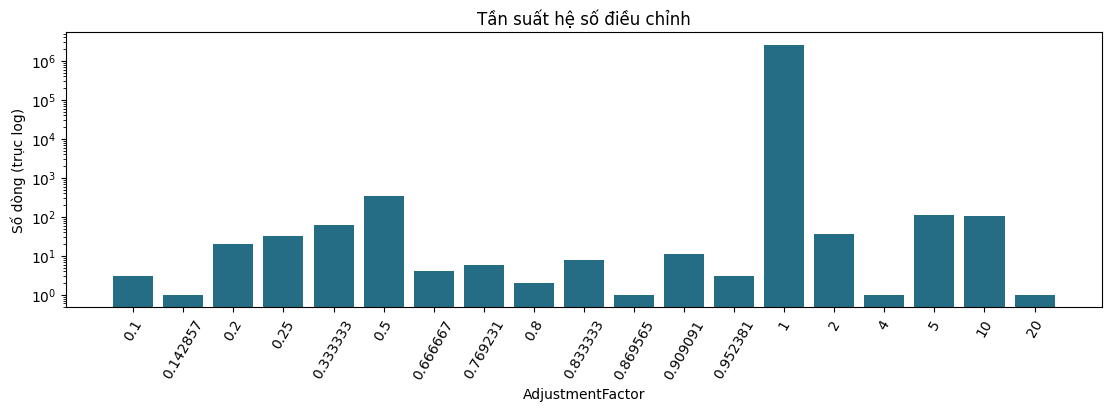

In [9]:
factor_counts = prices["AdjustmentFactor"].value_counts().sort_index()
print(f"Hệ số bằng 1: {factor_counts.get(1, 0):,} / {factor_counts.sum():,}")
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
factors = [f"{factor:g}" for factor in factor_counts.index]
ax.bar(factors, factor_counts.to_numpy(), color="#256D85")
ax.set(yscale="log", xlabel="AdjustmentFactor", ylabel="Số dòng (trục log)", title="Tần suất hệ số điều chỉnh")
ax.tick_params(axis="x", labelrotation=60)
plt.show()

Chỉ 753 dòng có hệ số khác 1. Dù hiếm, chia/gộp có thể tạo thay đổi giá lớn trên biểu đồ và trong đặc trưng lợi nhuận nếu dùng trực tiếp giá gốc.

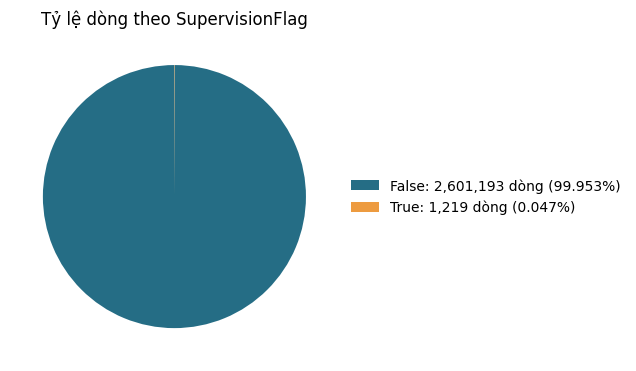

In [10]:
flag_counts = prices["SupervisionFlag"].value_counts().reindex([False, True], fill_value=0)
fig, ax = plt.subplots(figsize=(7.2, 3.6), layout="constrained")
wedges, _ = ax.pie(flag_counts, colors=["#256D85", "#ED9B40"], startangle=90)
labels = [
    f"{flag}: {count:,} dòng ({count / flag_counts.sum():.3%})"
    for flag, count in flag_counts.items()
]
ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title("Tỷ lệ dòng theo SupervisionFlag")
plt.show()

Biểu đồ cho thấy cờ giám sát hiếm ở cấp mã–phiên. Nếu thử dùng cờ cho mô hình hoặc bộ lọc giao dịch, cần so độ phủ và tỷ lệ thiếu giá ở các phiên có cờ.

## Target và OHLC theo thời gian

Trung vị Target phần phát triển: 0.00%
Số phiên có trung vị bằng 0: 97 / 1,205


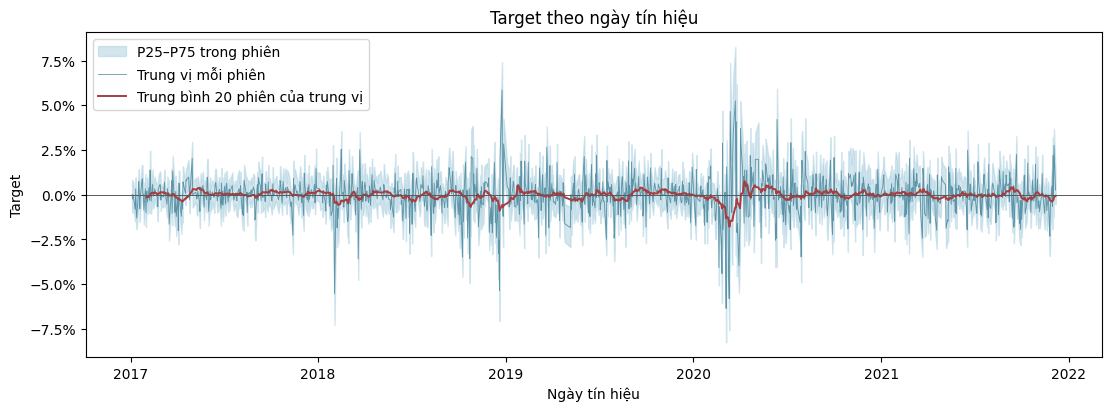

In [11]:
daily_target = (
    development_prices.groupby("Date")["Target"].quantile([0.25, 0.5, 0.75]).unstack()
    .rename(columns={0.25: "P25", 0.5: "P50", 0.75: "P75"})
)
rolling_median_mean = daily_target["P50"].rolling(20, min_periods=20).mean()
print(f"Trung vị Target phần phát triển: {development_prices['Target'].median():.2%}")
print(f"Số phiên có trung vị bằng 0: {daily_target['P50'].eq(0).sum():,} / {len(daily_target):,}")

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
ax.fill_between(daily_target.index, daily_target["P25"], daily_target["P75"],
                color="#A9CFDF", alpha=0.5, label="P25–P75 trong phiên")
ax.plot(daily_target["P50"], color="#256D85", lw=0.65, alpha=0.65, label="Trung vị mỗi phiên")
ax.plot(rolling_median_mean, color="#A63D40", lw=1.4, label="Trung bình 20 phiên của trung vị")
ax.axhline(0, color="0.35", linewidth=0.7)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set(xlabel="Ngày tín hiệu", ylabel="Target", title="Target theo ngày tín hiệu")
ax.legend(loc="upper left")
plt.show()

Biểu đồ dùng các nhãn đã hoàn tất trước mốc khóa. Dải P25–P75 thay đổi theo thời gian và thể hiện độ phân tán lợi nhuận giữa các mã trong từng ngày tín hiệu.

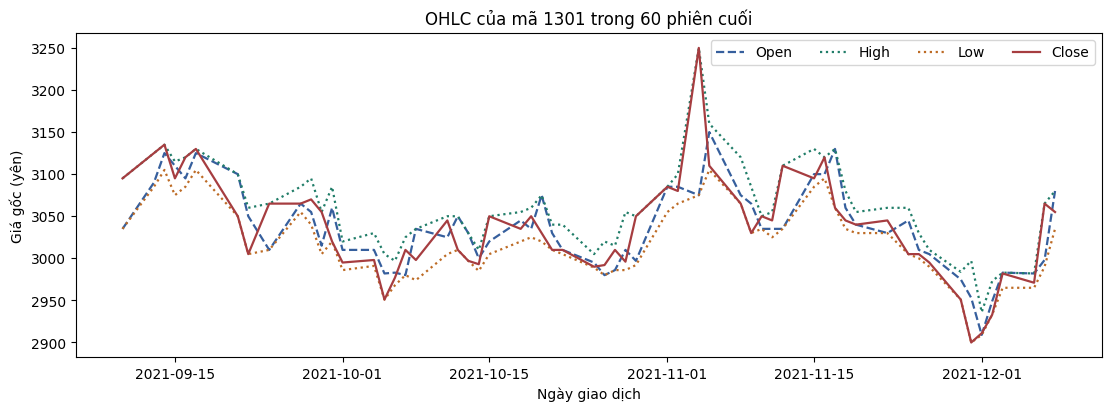

In [12]:
symbol_ohlc = prices.loc[prices["SecuritiesCode"].eq(1301), ["Date", "Open", "High", "Low", "Close"]]
market_days = pd.DatetimeIndex(development_prices["Date"].unique()).sort_values()[-60:]
recent_ohlc = symbol_ohlc.set_index("Date").reindex(market_days)

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
for column, color, line_style in [
    ("Open", "#365F9D", "--"), ("High", "#207D68", ":"),
    ("Low", "#BD6B25", ":"), ("Close", "#A63D40", "-"),
]:
    ax.plot(recent_ohlc.index, recent_ohlc[column], label=column,
            color=color, linestyle=line_style, lw=1.6)
ax.set(xlabel="Ngày giao dịch", ylabel="Giá gốc (yên)", title="OHLC của mã 1301 trong 60 phiên cuối")
ax.legend(ncol=4)
plt.show()

Bốn đường minh họa giá gốc của một mã trên đúng lịch 60 phiên. Việc các đường gần nhau chủ yếu phản ánh cùng thang giá. Muốn so với mã khác cần đưa về tỷ suất hoặc một thước đo đã chuẩn hóa.

## Chất lượng giá và nhãn theo phiên

Ba phần cuối dùng các nhãn hoàn tất trước 09/12/2021, mốc khóa mô hình. Các phần tổng quan phía trên mô tả toàn bộ dữ liệu ghép.

In [13]:
cutoff = pd.Timestamp("2021-12-09")
train_eda = prices.loc[
    label_end.lt(cutoff), ["Date", "SecuritiesCode", "Target"]
].copy()
calendar = pd.Series(sessions, index=sessions)
next_session = calendar.shift(-1)

valid_bar = prices[["Open", "High", "Low", "Close"]].notna().all(axis=1) & prices["Volume"].gt(0)
bar_lookup = pd.Series(valid_bar.to_numpy(), index=pd.MultiIndex.from_frame(
    prices[["Date", "SecuritiesCode"]]
))
train_eda["Có OHLCV hợp lệ"] = valid_bar.loc[train_eda.index]
train_eda["Nhãn bằng 0"] = train_eda["Target"].eq(0)
train_eda["Phiên t+1"] = train_eda["Date"].map(next_session)
train_eda["Phiên t+2"] = label_end.loc[train_eda.index]

for horizon in ("t+1", "t+2"):
    future_key = pd.MultiIndex.from_arrays([
        train_eda[f"Phiên {horizon}"], train_eda["SecuritiesCode"]
    ])
    train_eda[f"Có OHLCV ở {horizon}"] = bar_lookup.reindex(future_key, fill_value=False).to_numpy()

session_quality = train_eda.groupby("Date").agg(**{
    "Có dòng": ("SecuritiesCode", "size"),
    "Có OHLCV": ("Có OHLCV hợp lệ", "sum"),
    "Có OHLCV ở t+1": ("Có OHLCV ở t+1", "sum"),
    "Có OHLCV ở t+2": ("Có OHLCV ở t+2", "sum"),
    "Có nhãn": ("Target", "count"),
    "Nhãn bằng 0": ("Nhãn bằng 0", "sum"),
    "Số nhãn khác nhau": ("Target", "nunique"),
    "Phiên t+1": ("Phiên t+1", "first"),
    "Phiên t+2": ("Phiên t+2", "first"),
})
incident = pd.Timestamp("2020-10-01")
incident_window = session_quality.loc["2020-09-28":"2020-10-05"]
display(incident_window[[
    "Phiên t+1", "Phiên t+2", "Có dòng", "Có OHLCV",
    "Có OHLCV ở t+1", "Có OHLCV ở t+2", "Có nhãn", "Nhãn bằng 0",
]])
print("Các phiên chỉ có một giá trị Target trong phần train:")
display(session_quality.loc[session_quality["Số nhãn khác nhau"].eq(1), [
    "Phiên t+1", "Phiên t+2", "Có nhãn", "Nhãn bằng 0",
]])

,Phiên t+1,Phiên t+2,Có dòng,Có OHLCV,Có OHLCV ở t+1,Có OHLCV ở t+2,Có nhãn,Nhãn bằng 0
Date,,,,,,,,
2020-09-28,2020-09-29,2020-09-30,1986,1983,1981,1983,1986,29
2020-09-29,2020-09-30,2020-10-01,1986,1981,1983,0,1986,1986
2020-09-30,2020-10-01,2020-10-02,1986,1983,0,1984,1986,39
2020-10-01,2020-10-02,2020-10-05,1988,0,1986,1985,1988,44
2020-10-02,2020-10-05,2020-10-06,1989,1986,1985,1982,1988,85
2020-10-05,2020-10-06,2020-10-07,1990,1986,1983,1984,1990,65


Các phiên chỉ có một giá trị Target trong phần train:


,Phiên t+1,Phiên t+2,Có nhãn,Nhãn bằng 0
Date,,,,
2020-09-29,2020-09-30,2020-10-01,1986,1986


Ngày 01/10/2020 không có OHLCV hợp lệ. Ngày tín hiệu 29/09 có `t+2` rơi vào ngày đó và cả 1.986 nhãn đều bằng 0. Ngày tín hiệu 30/09 cũng đi qua sự cố nhưng vẫn có 1.947 nhãn khác 0. Đây là hai trường hợp cần thử độ nhạy khi huấn luyện và chấm. [Báo cáo sự cố của JPX](https://www.jpx.co.jp/english/corporate/news/news-releases/0060/20201019-01.html)

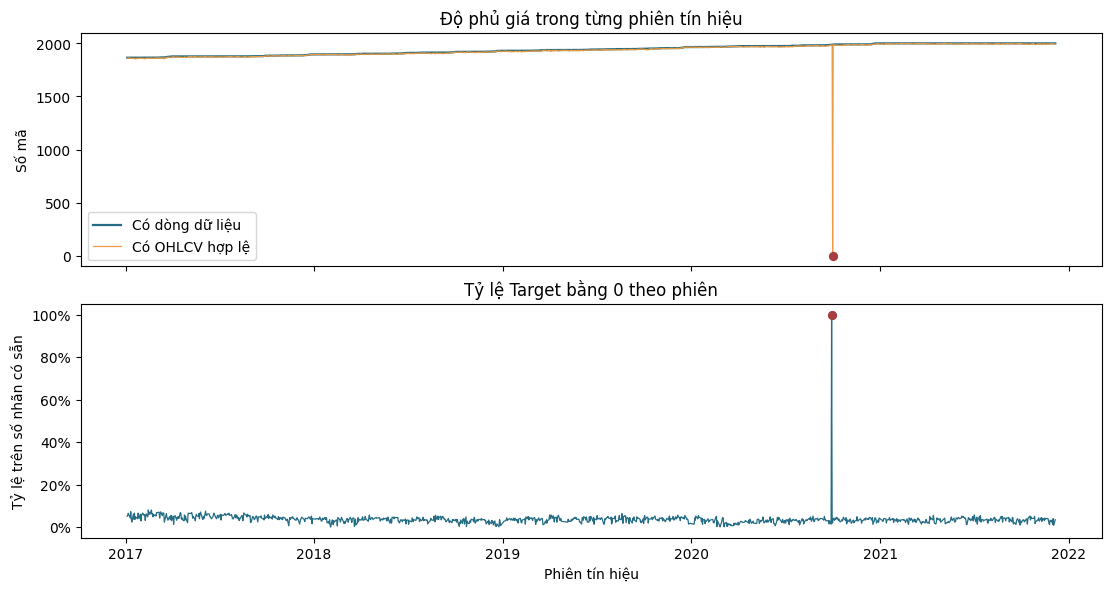

In [14]:
fig, (ax_bars, ax_zero) = plt.subplots(2, 1, sharex=True, figsize=(11, 5.8), layout="constrained")
ax_bars.plot(session_quality["Có dòng"], color="#256D85", lw=1.6, label="Có dòng dữ liệu")
ax_bars.plot(session_quality["Có OHLCV"], color="#ED9B40", lw=0.9, label="Có OHLCV hợp lệ")
ax_bars.scatter(incident, session_quality.loc[incident, "Có OHLCV"], color="#A63D40", s=32, zorder=3)
ax_bars.set(ylabel="Số mã", title="Độ phủ giá trong từng phiên tín hiệu")
ax_bars.legend(loc="lower left")

zero_share = session_quality["Nhãn bằng 0"].div(session_quality["Có nhãn"])
ax_zero.plot(zero_share, color="#256D85", lw=0.9)
signal_before_incident = session_quality.index[session_quality["Phiên t+2"].eq(incident)][0]
ax_zero.scatter(signal_before_incident, zero_share.loc[signal_before_incident], color="#A63D40", s=32, zorder=3)
ax_zero.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_zero.set(xlabel="Phiên tín hiệu", ylabel="Tỷ lệ trên số nhãn có sẵn", title="Tỷ lệ Target bằng 0 theo phiên")
plt.show()

Hai dấu đỏ thuộc hai ngày khác nhau. Một dấu đánh dấu ngày thiếu giá. Dấu còn lại đánh dấu ngày tín hiệu có toàn bộ nhãn bằng 0 vì chân trời `t+2` chạm ngày sự cố.

## Độ dài lịch sử theo mã

Minh họa điều kiện có 20 lợi nhuận 1 phiên liên tiếp, tương ứng 21 phiên có giá hợp lệ.

,Số phiên có dòng,Số phiên có OHLCV
count,2000.0,2000.0
mean,1167.3,1163.5
std,151.4,152.5
min,233.0,232.0
25%,1203.0,1202.0
50%,1203.0,1202.0
75%,1203.0,1202.0
max,1203.0,1202.0


Số mã xuất hiện sau phiên đầu: 135


Số phiên liên tiếp không có mã đủ cửa sổ từ ngày sự cố: 21
Phiên đầu có mã đủ cửa sổ trở lại: 2020-10-30


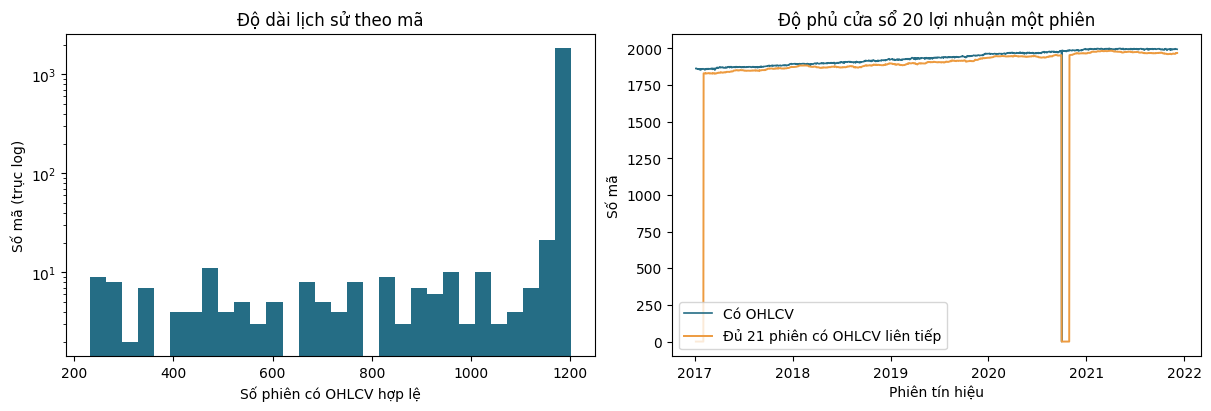

In [15]:
from matplotlib.dates import DateFormatter, YearLocator

stock_history = train_eda.groupby("SecuritiesCode").agg(**{
    "Phiên đầu": ("Date", "min"),
    "Phiên cuối": ("Date", "max"),
    "Số phiên có dòng": ("Date", "size"),
    "Số phiên có OHLCV": ("Có OHLCV hợp lệ", "sum"),
})
display(stock_history[["Số phiên có dòng", "Số phiên có OHLCV"]].describe().round(1))
print("Số mã xuất hiện sau phiên đầu:", stock_history["Phiên đầu"].gt(train_eda["Date"].min()).sum())

bar_panel = train_eda.pivot(index="Date", columns="SecuritiesCode", values="Có OHLCV hợp lệ")
train_sessions = sessions[sessions <= session_quality.index.max()]
bar_panel = bar_panel.reindex(train_sessions).eq(True)
window_size = 21
ready_counts = bar_panel.rolling(window_size, min_periods=window_size).sum().eq(window_size).sum(axis=1)

after_incident = ready_counts.loc[incident:]
first_ready = after_incident.loc[after_incident.gt(0)].index.min()
print(f"Số phiên liên tiếp không có mã đủ cửa sổ từ ngày sự cố: {int(after_incident.index.searchsorted(first_ready))}")
print(f"Phiên đầu có mã đủ cửa sổ trở lại: {first_ready:%Y-%m-%d}")

fig, (ax_hist, ax_ready) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ax_hist.hist(stock_history["Số phiên có OHLCV"], bins=30, color="#256D85", log=True)
ax_hist.set(xlabel="Số phiên có OHLCV hợp lệ", ylabel="Số mã (trục log)", title="Độ dài lịch sử theo mã")
ax_ready.plot(bar_panel.sum(axis=1), color="#256D85", lw=1.2, label="Có OHLCV")
ax_ready.plot(ready_counts, color="#ED9B40", lw=1.4, label="Đủ 21 phiên có OHLCV liên tiếp")
ax_ready.set(xlabel="Phiên tín hiệu", ylabel="Số mã", title="Độ phủ cửa sổ 20 lợi nhuận một phiên")
ax_ready.xaxis.set_major_locator(YearLocator())
ax_ready.xaxis.set_major_formatter(DateFormatter("%Y"))
ax_ready.legend(loc="lower left")
plt.show()

Có 135 mã xuất hiện sau ngày đầu. Sau sự cố, phải đến 30/10/2020 mới có mã đủ 21 phiên giá hợp lệ liên tiếp. Trong khoảng trống này, các đặc trưng đòi đủ 20 lợi nhuận một phiên liên tiếp chuyển sang thiếu hàng loạt.

## Độ phân tán của Target

IQR là chênh lệch giữa P75 và P25. So sánh IQR và độ lệch chuẩn giúp xem phần giữa và phần đuôi của phân bố.

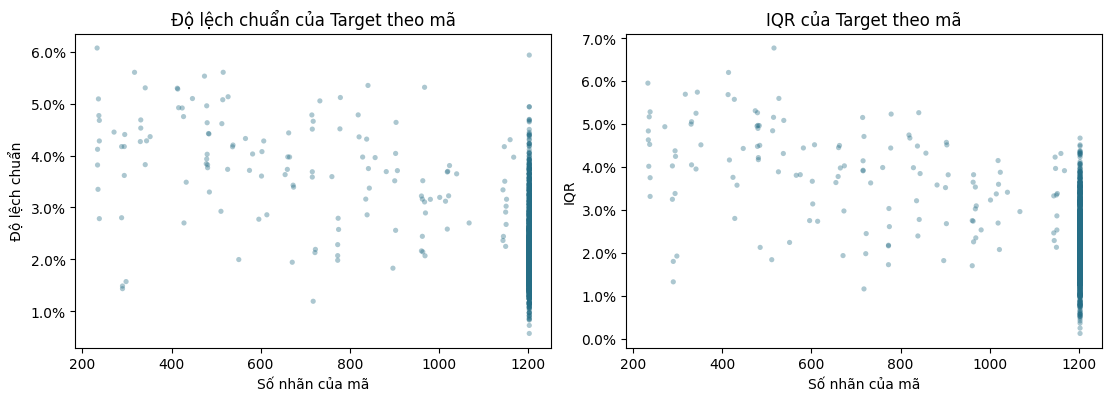

Năm phiên có độ lệch chuẩn Target cao nhất:


,Số nhãn,Độ lệch chuẩn,IQR
Date,,,
2020-03-17,1971,6.42%,7.84%
2020-03-18,1971,5.00%,6.22%
2020-03-19,1971,4.86%,5.76%
2020-11-06,1991,4.68%,4.22%
2020-03-13,1971,4.39%,5.74%


In [16]:
def target_dispersion(grouped):
    summary = grouped.agg(["count", "std"]).rename(columns={"count": "Số nhãn", "std": "Độ lệch chuẩn"})
    quartiles = grouped.quantile([0.25, 0.75]).unstack()
    return summary.assign(IQR=quartiles[0.75] - quartiles[0.25])

dispersion_by_stock = target_dispersion(train_eda.groupby("SecuritiesCode")["Target"])
dispersion_by_date = target_dispersion(train_eda.groupby("Date")["Target"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), layout="constrained")
for ax, column in zip(axes, ("Độ lệch chuẩn", "IQR")):
    ax.scatter(dispersion_by_stock["Số nhãn"], dispersion_by_stock[column],
               color="#256D85", s=14, alpha=0.38, edgecolors="none")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set(xlabel="Số nhãn của mã", ylabel=column, title=f"{column} của Target theo mã")
plt.show()

print("Năm phiên có độ lệch chuẩn Target cao nhất:")
most_dispersed = dispersion_by_date.nlargest(5, "Độ lệch chuẩn")
display(most_dispersed.assign(**{
    column: most_dispersed[column].map("{:.2%}".format)
    for column in ("Độ lệch chuẩn", "IQR")
}))

Bốn trong năm phiên có độ lệch chuẩn `Target` cao nhất nằm trong tháng 3/2020. Ngày 17/03 có độ lệch chuẩn 6,42% và IQR 7,84%. IQR cao cho thấy phần giữa của phân phối cũng rộng. Đây là gợi ý để chấm riêng các giai đoạn có độ phân tán cao.

## Giá thiếu và nhãn cực trị trong tập phát triển

In [17]:

import sys

sys.path.insert(0, str(project_root))
from src.preprocessing import eligible_bars
from src.release_experiment import CUTOFF

development = prices.loc[prices["Date"].lt(CUTOFF)].copy()
fully_observed = eligible_bars(development)
by_year = pd.DataFrame({"Năm": development["Date"].dt.year, "Thiếu giá tại t": ~fully_observed})
display(by_year.groupby("Năm")["Thiếu giá tại t"].agg(["size", "sum", "mean"]).round(4))
display(development.loc[~fully_observed].groupby("SecuritiesCode").size().nlargest(8)
        .rename("Số phiên thiếu giá của từng mã"))
calendar = pd.DatetimeIndex(development["Date"].unique()).sort_values()
lookup = pd.Series(calendar, index=calendar)
price_bars = development.set_index(["Date", "SecuritiesCode"])
known_label = development["Date"].map(lookup.shift(-2)).notna() & development["Target"].notna()
extreme = development.loc[known_label & development["Target"].abs().gt(.20), ["Date", "SecuritiesCode", "Target"]]
outputs = extreme.copy()
for horizon in (1, 2):
    keys = pd.MultiIndex.from_arrays([extreme["Date"].map(lookup.shift(-horizon)), extreme["SecuritiesCode"]])
    outputs[f"Thiếu Close t+{horizon}"] = price_bars["Close"].reindex(keys).isna().to_numpy()
    if horizon == 1:
        factors = price_bars["AdjustmentFactor"].reindex(keys)
        outputs["Có hệ số chia/gộp tại t+1"] = factors.notna().to_numpy() & factors.ne(1).to_numpy()
display(outputs.groupby(["Thiếu Close t+1", "Thiếu Close t+2", "Có hệ số chia/gộp tại t+1"]).size()
        .rename("Số nhãn có |Target| > 20%"))
outage = pd.read_csv(project_root / "artifacts/development_outage.csv")
display(outage.round(4))


,size,sum,mean
Năm,,,
2017,463722,1131,0.0024
2018,467672,1024,0.0022
2019,468295,1217,0.0026
2020,480842,3167,0.0066
2021,458000,1087,0.0024


SecuritiesCode
9733    354
2761    349
4628    288
1981    284
4365    282
1787    281
5918    281
4781    269
Name: Số phiên thiếu giá của từng mã, dtype: int64

Thiếu Close t+1  Thiếu Close t+2  Có hệ số chia/gộp tại t+1
False            False            False                        955
True             False            False                          3
Name: Số nhãn có |Target| > 20%, dtype: int64

,Scenario,Sessions,JPX Sharpe,Spread bps
0,Ridge original,700,0.0768,10.3911
1,Ridge remove affected evaluation dates,698,0.0768,10.3989
2,Ridge training pair,700,0.0768,10.3911
3,Ridge exclude affected training labels,700,0.0760,10.2808


Hai bảng đầu phân biệt thiếu giá tập trung ở một mã hay quanh một ngày. Nhãn có biên độ lớn được đối chiếu với dữ liệu giá và hệ số chia/gộp ở chân trời của nhãn. Đây là phân nhóm để kiểm tra, nguyên nhân của từng nhãn cực trị còn có thể cần thông tin sự kiện doanh nghiệp.

Bảng sự cố giữ nguyên ánh xạ `t+1/t+2`. Việc bỏ hai ngày khỏi phép chấm và việc bỏ nhãn trước khi fit là hai thí nghiệm khác nhau. [Thông báo của JPX](https://www.jpx.co.jp/english/corporate/news/news-releases/0060/20201019-01.html)

## Kiểm tra các đặc trưng giá

In [18]:

from src.features import FEATURE_COLUMNS, build_price_features
from src.final_pipeline import PRICE_INPUTS

inputs = development[PRICE_INPUTS]
features = build_price_features(inputs, include_liquidity=True)
labeled = features.merge(
    development.loc[fully_observed & known_label, ["Date", "SecuritiesCode", "Target"]],
    on=["Date", "SecuritiesCode"], validate="one_to_one",
)
columns = list(FEATURE_COLUMNS)
monthly_coverage = labeled.groupby(labeled["Date"].dt.to_period("M"))[columns].agg(lambda x: x.notna().mean())
display(monthly_coverage.loc["2020-09":"2020-11"].round(3))
correlations = []
for date, day in labeled.groupby("Date"):
    record = {"Date": date}
    for column in columns:
        pair = day.loc[day[column].notna(), [column, "Target"]]
        record[column] = (pair[column].rank().corr(pair["Target"].rank())
                          if pair[column].nunique() > 1 and pair["Target"].nunique() > 1 else float("nan"))
    correlations.append(record)
display(pd.DataFrame(correlations).set_index("Date").agg(["count", "mean", "std"]).T.round(4))


,return_1,return_5,return_20,intraday_range,volatility_20,relative_turnover_20
Date,,,,,,
2020-09,0.998,0.997,0.997,1.0,0.988,0.988
2020-10,0.950,0.950,0.947,1.0,0.047,0.047
2020-11,0.999,0.998,0.997,1.0,0.987,0.987


,count,mean,std
return_1,1199.0,-0.0027,0.1111
return_5,1195.0,-0.0054,0.1180
return_20,1180.0,-0.0069,0.1229
intraday_range,1201.0,-0.0149,0.1399
volatility_20,1161.0,-0.0162,0.1635
relative_turnover_20,1161.0,-0.0035,0.0589


Độ phủ cửa sổ có thể giảm nhiều hơn độ phủ OHLCV đúng ngày, vì một khoảng trống ảnh hưởng nhiều điểm liên tiếp. IC trung bình ở bảng dưới mô tả từng biến trên các mã có cả giá trị đặc trưng lẫn nhãn trong phiên. Đây là phép khám phá trước khi so sánh mô hình trên các cửa sổ đã định.